# The output

A run of the steady-state example, read with `lucifer.stats` and `lucifer.beam`.

In [1]:
from lucifer import Lucifer

L = Lucifer("lucifer.toml", threads=4)
L.run()

exit,0
out_root,steady_state
directory,/private/tmp/lucifer_bwm6bxc6
stats file,steady_state.stats.h5
files,"steady_state-final.beam.h5, steady_state-final.wf.h5, steady_state.stats.h5"


## The stats file

The file describes itself: every dataset carries its unit and the axes it runs over.

In [2]:
st = L.output.stats
st

file,steady_state.stats.h5
format,bmad-stats 1.0
records,1105
element ends,48
slices,1
s,0 to 57 m
components,x
harmonics,none


In [3]:
st.axis_names

('bmad',
 'bmad_col',
 'bmad_t',
 'ele',
 'element_end',
 'mode',
 'plane',
 'record',
 'slice',
 'wavefront',
 'wavefront_col')

In [4]:
st.units["field/total/power"], st.axes["field/total/power"]

('W', ('record', 'slice'))

In [5]:
st.coord("plane")

('x', 'y', 'z')

In [6]:
st.params["run"]["ran_seed"]

12345

## A dataset by hand

The power is a record-by-slice array, here one slice.

In [7]:
power = st["field/total/power"]
power.shape

(1105, 1)

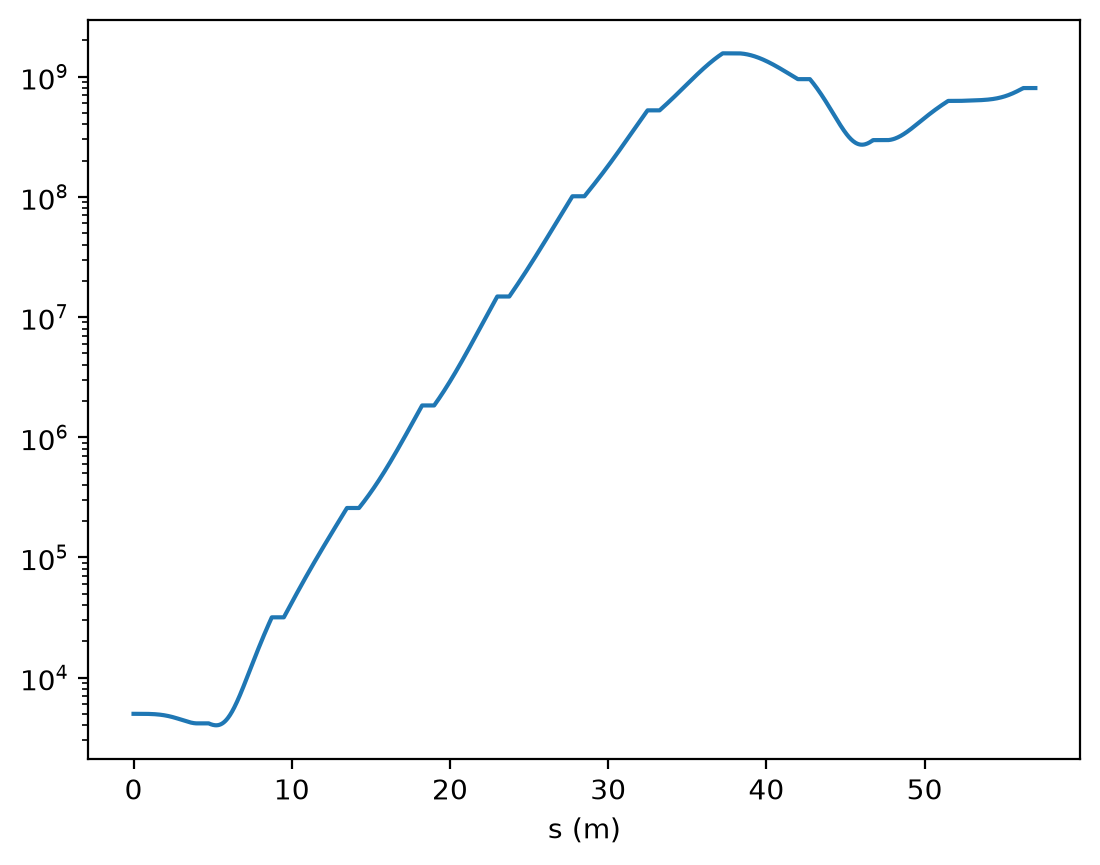

In [8]:
import matplotlib.pyplot as plt

plt.semilogy(st.s, power.sum(axis=1))
plt.xlabel("s (m)");

## The beam dump

`lucifer.beam` reads a particle dump into per-slice arrays, given the wavelength the run used.

In [9]:
from lucifer.beam import read_slices

dump = L.output.cwd / "steady_state-final.beam.h5"
slices = read_slices(dump, wavelength=L.input.field.lambda0)

In [10]:
len(slices), sorted(slices[0])

(1, ['current', 'gamma', 'n', 'px', 'py', 'pz', 'theta', 'weight', 'x', 'y'])

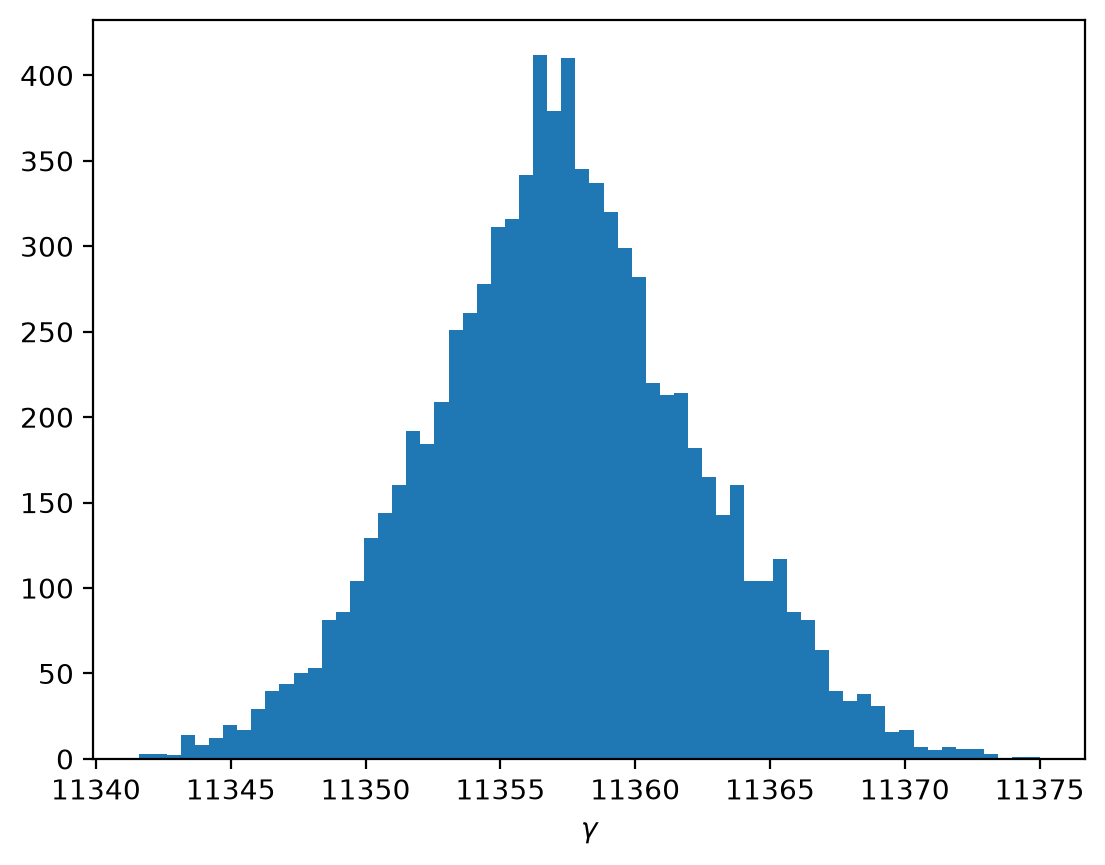

In [11]:
plt.hist(slices[0]["gamma"], bins=64)
plt.xlabel(r"$\gamma$");